# 01 — FrozenLake Dynamic Programming

알려진 P(s′,r,terminated|s,a)를 사용하는 정확한 기대값 계산이다. 고정 정책의 Policy Evaluation,
Policy Improvement를 반복하는 Policy Iteration, Optimality Backup의 Value Iteration을 구분한다.
DP는 Replay 경험 학습이나 추론용 Model.forward가 아니며, NumPy 계산을 강제로 Learner에 넣지 않는다.

### 실행 설정
`MODULARRL_FAST=1`은 CI용 FAST, 기본값은 FULL입니다. 각 Notebook은 독립 Kernel에서 실행합니다. 처음부터 Run All하면 RNG·Model·학습 상태를 다시 만듭니다.

In [1]:
from pathlib import Path
import os, sys, json
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').exists())
if str(root) not in sys.path: sys.path.insert(0, str(root))
import gymnasium as gym
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from copy import deepcopy
from collections import deque
from modular_rl.model import Model
from modular_rl.component.representation import IdentityRepresentation, MLPRepresentation
from modular_rl.component.estimator import TabularVEstimator, TabularQEstimator, DiscreteQEstimator
from modular_rl.component.action_selector import EpsilonGreedyActionSelector
from modular_rl.component.target_generator import TD0TargetGenerator, MonteCarloReturnGenerator, NStepTargetGenerator
from modular_rl.component.update_rule import TabularVUpdateRule, TabularQUpdateRule, TDLossUpdateRule
from modular_rl.component.buffer import ReplayBuffer, SequenceReplayBuffer
from modular_rl.data import Transition, Episode
from modular_rl.learner import (TabularQLearner, TabularSARSALearner, TabularTD0PredictionLearner,
    MCPredictionLearner, TabularMCControlLearner, OffPolicyMCPredictionLearner, OffPolicyMCControlLearner, DQNLearner)
from modular_rl.dp import policy_evaluation, policy_iteration, value_iteration, uniform_policy, action_values
from notebooks.gymnasium.tutorial_utils import (frozenlake_mdp, evaluate, history, record, frozen_report, neural_report)
FAST = os.environ.get('MODULARRL_FAST', '0') == '1'  # 기본 FULL, CI는 FAST=1
SEED = 7
GAMMA = .99
np_rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
plt.close('all')
print({'mode': 'FAST' if FAST else 'FULL', 'seed': SEED, 'gamma': GAMMA, 'device': 'cpu'})

{'mode': 'FAST', 'seed': 7, 'gamma': 0.99, 'device': 'cpu'}


In [2]:
env = gym.make('FrozenLake-v1', map_name='4x4', is_slippery=False, max_episode_steps=1000)
eval_env = gym.make('FrozenLake-v1', map_name='4x4', is_slippery=False, max_episode_steps=100)
S, A = int(env.observation_space.n), int(env.action_space.n)
print(env.observation_space, env.action_space)
desc = env.unwrapped.desc.copy()

Discrete(16) Discrete(4)


In [3]:
mdp = frozenlake_mdp(env)  # 알려진 kernel을 DP에만 전달한다.
policy = uniform_policy(mdp)
reference = policy_evaluation(mdp, policy, gamma=GAMMA, theta=1e-12)
pi_result = policy_iteration(mdp, gamma=GAMMA, theta=1e-12)
vi_result = value_iteration(mdp, gamma=GAMMA, theta=1e-12)
print('evaluation', reference.converged, reference.iterations)
print('policy iteration', pi_result.converged, pi_result.iterations)
print('value iteration', vi_result.converged, vi_result.iterations)
print('optimal value difference', float(np.max(np.abs(pi_result.values-vi_result.values))))
print('uniform V', reference.values.reshape(4,4))

evaluation True 116
policy iteration True 3
value iteration True 7
optimal value difference 0.0
uniform V [[0.01235614 0.01042446 0.01933844 0.00947775]
 [0.01478705 0.         0.03889445 0.        ]
 [0.03260247 0.08433764 0.13781085 0.        ]
 [0.         0.17034482 0.43357944 0.        ]]


### 계산된 정책을 실제 Gymnasium에서 실행
종료 전이는 Bootstrap하지 않는다. 동률 최대 행동에 균등 확률을 주는 DP 정책을 별도의 환경에서 확인한다. Model/TargetGenerator/UpdateRule/Buffer는 이 계산에 필요 없다.

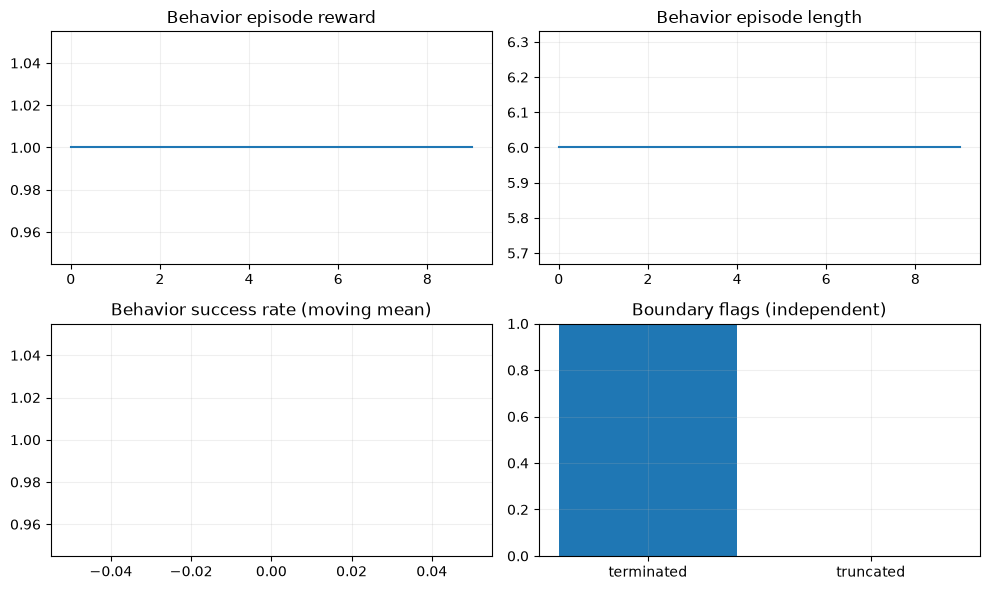

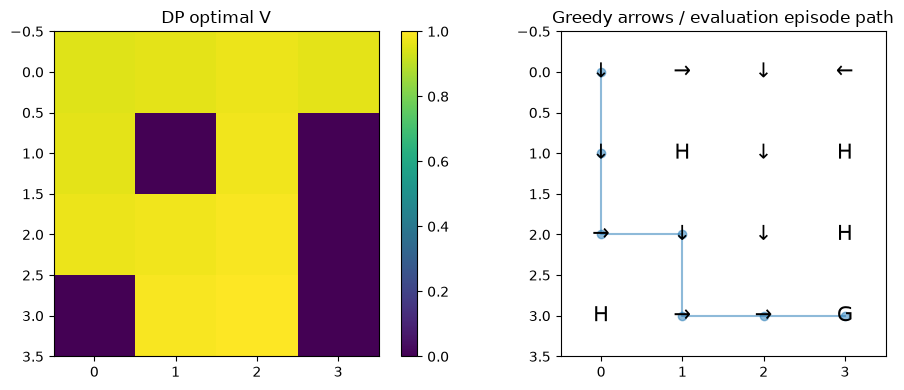

DP optimal V [0.951  0.9606 0.9703 0.9606 0.9606 0.     0.9801 0.     0.9703 0.9801
 0.99   0.     0.     0.99   1.     0.    ]
RESULT {"environment_steps": 60, "episodes": 10, "evaluation_mean_reward": 1.0, "evaluation_success": 1.0, "terminated_rate": 1.0, "truncated_rate": 0.0}


In [4]:
log = history()
for episode in range(10 if FAST else 100):
    observation, _ = env.reset(seed=SEED if episode == 0 else None)
    total, length = 0., 0
    while True:
        action = np_rng.choice(A, p=pi_result.policy[observation])
        observation, reward, terminated, truncated, _ = env.step(int(action))
        reward = float(reward)  # 학습 reward의 floating 계약
        total += reward; length += 1
        if terminated or truncated: break
    record(log, total, length, terminated, truncated)
evaluation = evaluate(eval_env, lambda state: int(vi_result.policy[state].argmax()), episodes=5 if FAST else 100)
summary = frozen_report(desc, log, vi_result.values, evaluation,
                        greedy_actions=vi_result.policy.argmax(-1), label='DP optimal V')
env.close(); eval_env.close()

### 이번 조합에서 드러난 API 특성
DP가 아는 전체 전이 kernel은 MC/TD Learner나 Dyna의 학습 World Model에 주지 않는다. Model 생성과 Buffer 호출이 없다는 점이 이 방법의 책임 경계다.

### API 사용성 기록 — 아래 빈칸을 직접 수정해 보세요

|질문|실행 후 관찰/개선 제안|
|---|---|
|Model 생성이 자연스러운가?| |
|Learner 구성은 직관적인가?| |
|TargetGenerator를 선택하기 쉬운가?| |
|Buffer의 사용법이 일관적인가?| |
|Experience 자료형을 직접 조작할 필요가 있는가?| |
|학습 호출이 간결한가?| |
|Algorithm-specific 코드가 얼마나 필요한가?| |
|불필요한 자료형 변환이 존재하는가?| |
|API만 보고 학습 과정이 이해되는가?| |
|공용 컴포넌트로 옮길 필요가 있는 코드가 있는가?| |

FAST는 연결과 Shape 검사용이며 성능 판정이 아니다. FULL은 실제 학습용이다.
Seed 하나의 성공률로 알고리즘의 정확성을 판단하지 않는다. `terminated`와 `truncated`는
독립적인 flag이며 실제 마지막 관측을 저장한다. 아래 helper는 시각화·평가만 담당하고 학습을 숨기지 않는다.